<a href="https://colab.research.google.com/github/mshmatsuda/deep-learning-from-scratch/blob/main/03_6_01_MNIST%E3%83%87%E3%83%BC%E3%82%BF%E3%82%BB%E3%83%83%E3%83%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **１．「ゼロつく」が用意しているデータのダウンロード**

指定されたURLからダウンロードし、実行フォルダに移動

In [ ]:
# 本のリポジトリ名（住所）を一度に打ち込んだみたがうまくいかなかった。なので、パーツにわけておく（エラーを回避するため今回特別措置をとる）
# 本のリポジトリ名（住所）をパーツに分けて合体させる


domain = "https://github.com"
repo_path = "/oreilly-japan/deep-learning-from-scratch.git"
full_url = domain + repo_path

# 合体させた正しいURLでダウンロードを実行する
!git clone {full_url}
%cd deep-learning-from-scratch


Cloning into 'deep-learning-from-scratch'...
remote: Enumerating objects: 573, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 573 (delta 3), reused 0 (delta 0), pack-reused 558 (from 2)
Receiving objects: 100% (573/573), 10.61 MiB | 16.74 MiB/s, done.
Resolving deltas: 100% (290/290), done.
/content/deep-learning-from-scratch/deep-learning-from-scratch


Google Colabにおいて、! と % は「Python以外の命令を実行するための特殊な記号」です。<br>
それぞれの役割は以下のように明確に分かれています。
## 1. 「!」（システムコマンドの実行）
「!」は、Colabの後ろで動いているLinuxシステム（OS）に対して、直接コマンドを送るための記号です。

* 役割: Pythonのプログラムではなく、パソコンのターミナル（コマンドプロンプト）で実行するような命令を出します。
* コードの意味: !git clone {full_url} は、「GitHubから指定したURLのソースコードを、このColab環境にダウンロードしてくれ」というLinuxへの命令になります。
* その他の例:
  * !ls （フォルダ内の一覧を表示）
  * !pip install numpy （外部ライブラリをインストール）

------------------------------
## 2. 「%」（マジックコマンドの実行）
「%」は、Colab（Jupyter Notebook）自身の環境や設定を操作・変更するための記号（マジックコマンド）です。

* 役割: Colabの現在の設定（作業している場所や、ノートブックの挙動）をその場で切り替えます。
* コードの意味: %cd deep-learning-from-scratch は、「Colabの現在の作業フォルダ（カレントディレクトリ）を deep-learning-from-scratch に移動せよ」という命令です。
* その他の例:
  * %pwd （今自分がどのフォルダにいるか確認）
  * %matplotlib inline （グラフをノートブック内にインライン表示させる設定）

------------------------------
## 💡 なぜ !cd ではなく %cd なのか？（重要な違い）
ここが一番引っかかりやすいポイントです。<br>
もし !cd deep-learning-from-scratch と書くと、その1行を実行した一瞬だけフォルダが移動し、次の行を実行するときには元のフォルダに勝手に戻ってしまいます。<br>
なぜなら、! は実行するたびに「新しくLinuxの画面を開いて、閉じる」という動きをするからです。<br>
ノートブック全体で「ずっとそのフォルダに移動したまま作業したい」という場合は、Colab自体の設定を固定する必要があるため、必ず %cd を使う必要があります。<br>



<br><br>

# **２．MNISTデータを読み込むための『特製プログラム』の準備**

特製プログラム（load_mnist）を準備
* ・sysとosをインポート
* ・ひとつ上のフォルダを探索範囲として広げること
* ・dataset フォルダの中にある mnist.py というファイルから、load_mnist という関数（機能）を持ってきて使えるようにする

In [ ]:
import sys, os
sys.path.append(os.pardir)
from dataset.mnist import load_mnist

「ゼロつく」で最初に出てくるこの3行は、プログラミング初心者にとって最初の大きな壁になりやすいポイントです。
<br><br>
結論から言うと、このコードは「1つ上のフォルダ（親ディレクトリ）にある、本のサンプルコードが入ったフォルダから、MNISTデータを読み込むための『特製プログラム』を引っ張ってくる」という準備をしています。
<br>
------------------------------<br>
##＜ 1行ずつの詳しい解説 ＞<br>
<br>
① import sys, os<br>
Pythonが標準で用意している、システム（sys）やパソコンのファイル操作（os）に関する基本機能を呼び出しています。
<br>
<br>
② sys.path.append(os.pardir)<br>
ここが一番の難所です。

* os.pardir は「親ディレクトリ（1つ上のフォルダ）」という意味です。
* sys.path は「Pythonが探しに行くフォルダのリスト」
* sys.path.append(...) は、Pythonに「プログラムを探す場所（検索パス）を追加してね」と指示する命令です。<br>


##＜なぜこれが必要なのか？＞<br>
3章6節のコード（neuralnet_mnist.pyなど）は、通常 ch03 というフォルダの中に保存して実行します。しかし、MNISTデータをダウンロードするためのプログラム（mnist.py）は、1つ上の階層にある dataset というフォルダの中にあります。<br>
Pythonは通常、自分が今いるフォルダ（ch03）の中しかプログラムを探さないため、そのままでは dataset フォルダを見つけられずにエラーになってしまいます。<br>
そこで、この行を使って「1つ上のフォルダもプログラムの探査範囲に含めてね！」とPythonにお願いしているのです。<br><br>
③ from dataset.mnist import load_mnist<br>
②の手順で1つ上のフォルダが探せるようになったので、「dataset フォルダの中にある mnist.py というファイルから、load_mnist という関数（機能）を持ってきて使えるようにする」という命令をしています。

------------------------------
## 💡 実行するための注意点
このコードが正しく動くためには、本の公式GitHubなどからダウンロードしたフォルダ構造がそのまま維持されていることが前提になります。<br>
もし以下のようなフォルダ配置になっていない場合、ModuleNotFoundError というエラーが出てしまいます。<br>

本のデータ（ルートフォルダ）<br>
├── dataset/             ← ここに mnist.py が入っている<br>
└── ch03/                ← いま自分が作業しているフォルダ（ここにプログラムを置く）<br><br>

もし、ご自身のパソコンで「自分で作った新しいフォルダ」の中にポツンとプログラムだけを書いて実行している場合は、この3行がうまく機能しません。<br>
その場合は、公式の dataset フォルダを自分の作業フォルダと同じ場所にコピーしてくるなどの対策が必要です。<br>



In [ ]:
# MNISTデータの読み込み（最初の1回だけ、データのダウンロードに数十秒かかります）
# 訓練用の画像データ一式(x_train, t_train)とテスト用の画像データ一式(x_test, t_test)

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, flatten=True)

# 読み込まれたデータの「形（形状）」を確認してみる

print("x_train shape:", x_train.shape)
print("t_train shape:", t_train.shape)


x_train shape: (60000, 784)
t_train shape: (60000,)


このコードは、一言でいうと「手書き数字の画像データと、それぞれの正解（0〜9の数字）をパソコンのメモリ上に読み込んで、中身のサイズを確認している」という処理を行っています。<br><br>

------------------------------
## ① 前半の長い1行（データの読み込み）

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, flatten=True)
<br><br>
ここでは、先ほど準備した「MNISTデータセット」からデータを一気に引っ張ってきて、4つの変数（箱）に分けて入れています。<br><br>
この4つの箱は、機械学習で定番の「訓練用」と「テスト用」に分かれています。

| 変数名 | 中身（データの内容） | 何に使うの？ |
|---|---|---|
| x_train | 訓練用の 画像データ（6万枚） | ニューラルネットワークを勉強（学習）させるための画像です。 |
| t_train | 訓練用の 正解ラベル（6万個） | 「上の画像は『5』ですよ」という、人間の書いた答えです。 |
| x_test | テスト用の 画像データ（1万枚） | 学習が終わったネットワークの実力を試すための本番用画像です。 |
| t_test | テスト用の 正解ラベル（1万個） | テスト画像に対する、答え合わせ用の正解データです。 |

<br>

* 3章6節では、すでに「学習」が終わっている「完成済みのパラメータ」を使う。「学習」用の訓練用データ(x_train, t_train)は今回使わない。
* 今回は後半のテスト用データ（x_test, t_test）だけを使ってニューラルネットワークの実力を測ります。<br><br>

------------------------------
## ② 後半の2行（サイズ・形の確認）

print("x_train shape:", x_train.shape)<br>
print("t_train shape:", t_train.shape)
<br><br>
Pythonの .shape という命令を使うと、データの「画像が何枚あって、1枚あたり何マスのデータなのか」という全体の形（形状）を教えてくれます。<br>
先ほど画面に表示された結果は、まさにこの処理の成果です。

* x_train shape: (60000, 784)<br>
👉 「訓練用の画像が 6万枚 あって、1枚あたり 784マス（縦28×横28マスを1列に並べたもの）でできていますよ」<br><br>
* t_train shape: (60000,)<br><br>
👉 「それに対応する正解の数字（0〜9）が 6万個 入っていますよ」ということを確認しています。<br><br>
------------------------------
一言でまとめると、「AIにテストを解かせるために、問題用紙（画像）と解答用紙（正解）を机の上に並べて、問題数がちゃんと揃っているか数えた状態」になります。


## 📊 表示された数字（shape）の超重要ポイント
<br><br>① x_train shape: (60000, 784)

* 60000：手書き数字の画像が、全部で 6万枚 入っているという意味です。
* 784：画像1枚あたりのデータ量（数字の個数）です。
<br><br>手書き数字の画像は、もともと「縦28マス × 横28マス」のサイズで作られています。$28 \times 28$ を計算すると 784 になりますよね。<br>コードの引数で flatten=True（平らにつぶす）としたため、2次元の画像が横一列の784個の数字の並びとして格納されています。

つまり、x_train は「784個のピクセル（マスの色）が並んだ画像が、6万枚セットになった巨大なリスト」です。<br><br>

## ② t_train shape: (60000,)

* 60000：正解ラベル（答え）が 6万個 入っているという意味です。
* x_train の6万枚の画像に対して、「この画像は『5』」「次の画像は『0』」といった、人間の書いた本物の答え（0〜9の数字）が順番に1対1で入っています。

------------------------------
ここまでの流れで、ニューラルネットワークに入力するための「画像データ」と「答え」の準備がバッチリ整いました。
このあと本では、「画像を表示してみる（mnist_show.pyの解説）」か、あるいは「学習済みの重みを使って実際に数字を予測させてみる（ニューラルネットワークの推論処理）」へと進んでいきます。



### ＜もう少しつっこんでみよう＞

プログラミング初心者の方が特に「おや？」と引っかかりやすい、Pythonならではの重要なルールについて2つの視点から分かりやすく解説します。

------------------------------
## 1. 左側の (x_train, t_train), (x_test, t_test) という書き方の意味
<br>これはPythonの「アンパック（荷解き）」という非常に便利な仕組みを使っています。<br>
load_mnist() という関数は、実行すると「4つのデータ（訓練画像、訓練正解、テスト画像、テスト正解）」をセットにして、一気にまとめて返してくれます。<br>※ちなみに、load_mnist関数は著者が定義したものだ。<br><br>
左側の書き方は、その送られてきた4つのデータを「本と同じ並び順のまま、4つの引き出しに一発で自動仕分けしてね！」と指示している状態です。<br>
イメージとしては以下のような仕分けが行われています。

* 📦 届けられた荷物: ( [6万枚の画像], [6万個の正解] ), ( [1万枚の画像], [1万個の正解] )
* 📦 仕分け先（左側）: ( x_train, t_train ), ( x_test, t_test )

このように、カッコの形を右側（関数が返すデータの形）と完全に一致させておくことで、1行書くだけでそれぞれの変数（引き出し）に綺麗にデータが収まる仕組みになっています。
<br>

------------------------------
## 2. load_mnist() の右側につくカッコと中身の意味
関数（命令）の右側につく () は、「この関数をこういう条件で動かしてください」という設定メーター（引数：ひきすう）を渡すためのものです。<br>
今回指定されている2つの設定メーターには、以下のような非常に重要な意味があります。<br>
## ① normalize=True （正規化する）

* 意味: 画像の「色の濃さ（ピクセル値）」を 0.0 〜 1.0 の間の数字に変換して受け取る、という設定です。
* なぜやるの？: 本来、手書き数字の画像データは「0（真っ黒）〜255（真っ白）」の間の整数で記録されています。しかし、ニューラルネットワークに大きな数字（255など）をそのまま入力して計算させると、計算の途中で数値が大きくなりすぎてパンクしたり、学習がうまく進まなくなったりします。あらかじめ 0.0〜1.0 の扱いやすい小さな小数に変換しておくことで、AIが正確に計算できるようになります。

## ② flatten=True （平らにつぶす）

* 意味: 縦28マス・横28マスある画像を、横一列に並んだ「784個の数字」に変形して受け取る、という設定です。
* なぜやるの？: 3章で実装するニューラルネットワーク（行列の掛け算）は、入力データが「横一列の並び（1次元配列）」になっている必要があります。本来の形（縦28×横28の2次元）のままだと計算の形が合わずにエラーになってしまうため、あらかじめ True（はい、平らにします）と設定して、AIが計算しやすい形に並べ替えてもらっています。

------------------------------
一言でまとめると、この1行は「AIが今すぐ計算できるように『数値を小さくして（normalize）』『横一列に並べ替えた（flatten）』状態のデータを、4つの引き出しに綺麗に仕分けて取り出した」という処理を行っています。


簡単に言うと、Pythonでは関数が複数のデータをまとめて返すとき、受け取る側も同じ形・同じ順番で並べるだけで、自動的に中身を分解してそれぞれの変数に割り当ててくれます。<br><br>
このコードは、まさにその仕組みを利用して「4つのデータを一発でそれぞれの引き出し（変数）に仕分ける」という役割を持っています。



# **MNIST画像を表示させてみる**

正解のラベル（数字）: 5
変形前の形: (784,)
変形後の形: (28, 28)


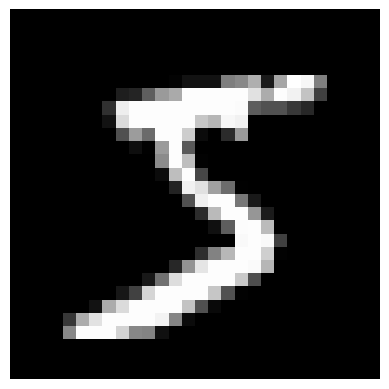

In [ ]:
import numpy as np
from dataset.mnist import load_mnist

# 本の「PILのインポート」を削除し、matplotlibだけにします
# 画像を表示するためのライブラリとしてmatplotlibを新しく呼び出す

import matplotlib.pyplot as plt


# 2. Colab用の画像表示関数に書き換えます（PILの代わりにmatplotlibを使用）

def img_show(img):
  # NumPy配列のデータをそのまま直接表示できます
    plt.imshow(img, cmap='gray') # 白黒画像（グレースケール）として指定
    plt.axis('off')             # 周りの目盛りを消す
    plt.show()                  # Colabの画面内に画像を出力する

(x_train, t_train), (x_test, t_test) = load_mnist(flatten=True, normalize=False)

img = x_train[0]
label = t_train[0]
print("正解のラベル（数字）:", label)

print("変形前の形:", img.shape)
img = img.reshape(28, 28)
print("変形後の形:", img.shape)

# これでColabの画面に直接画像が表示されます！
img_show(img)